In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
from tqdm import tqdm

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [2]:
DATA_ROOT = './'

transform_train = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)),
])
transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)),
])

train_dataset = torchvision.datasets.CIFAR10(root=DATA_ROOT, train=True, download=True, transform=transform_train)
test_dataset = torchvision.datasets.CIFAR10(root=DATA_ROOT, train=False, download=True, transform=transform_test)

classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

sample_img, sample_label = train_dataset[0]
print(f"  Обучающая выборка: {len(train_dataset)} примеров")
print(f"  Тестовая выборка:  {len(test_dataset)} примеров")
print(f"  Форма одного изображения: {sample_img.shape} (Каналы, Высота, Ширина)")
print(f"  Тип метки: {type(sample_label).__name__}, значение: {sample_label}")
print(f"  Классы: {classes}")

  Обучающая выборка: 50000 примеров
  Тестовая выборка:  10000 примеров
  Форма одного изображения: torch.Size([3, 32, 32]) (Каналы, Высота, Ширина)
  Тип метки: int, значение: 6
  Классы: ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')


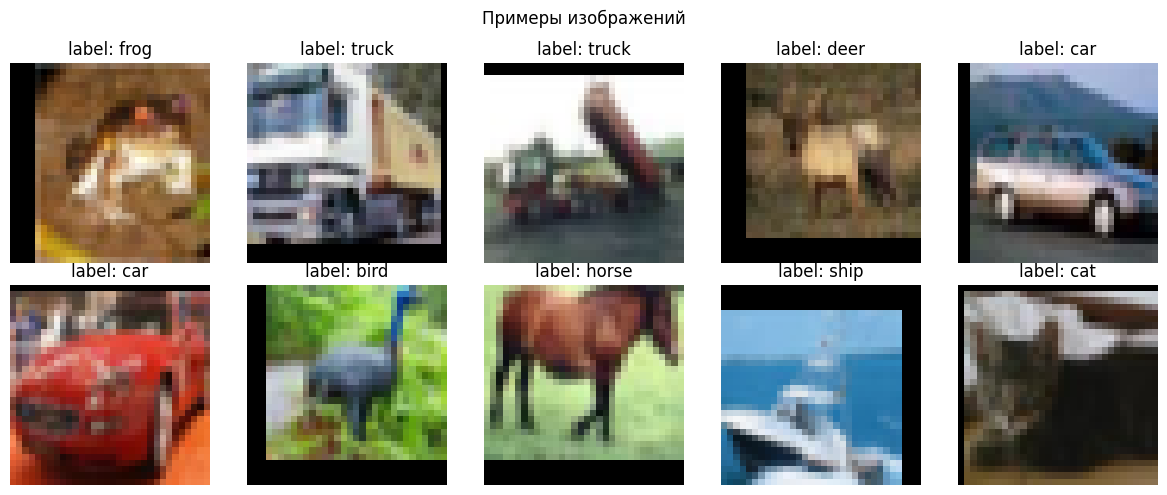

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
mean = torch.tensor([0.4914, 0.4822, 0.4465]).view(3, 1, 1)
std  = torch.tensor([0.2470, 0.2435, 0.2616]).view(3, 1, 1)

for i, ax in enumerate(axes.flat):
    img, label = train_dataset[i]
    img_disp = img * std + mean
    ax.imshow(np.transpose(img_disp.numpy(), (1, 2, 0)))
    ax.set_title(f"label: {classes[label]}")
    ax.axis('off')
plt.suptitle("Примеры изображений")
plt.tight_layout()
plt.show()

In [4]:
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False)
        self.bn = nn.BatchNorm2d(out_ch)
        self.relu = nn.ReLU(inplace=True)
    def forward(self, x):
        return self.relu(self.bn(self.conv(x)))


class CIFAR10CNN(nn.Module):
    def __init__(self, num_classes=10, dropout=0.3):
        super().__init__()
        self.block1 = nn.Sequential(ConvBlock(3, 32), ConvBlock(32, 32), nn.MaxPool2d(2, 2))
        self.block2 = nn.Sequential(ConvBlock(32, 64), ConvBlock(64, 64), nn.MaxPool2d(2, 2))
        self.block3 = nn.Sequential(ConvBlock(64, 128), ConvBlock(128, 128), nn.MaxPool2d(2, 2))

        self.gap = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.gap(x)
        x = torch.flatten(x, 1)
        return self.fc(self.dropout(x))


model = CIFAR10CNN().to(device)
print(f"Обучаемых параметров: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

Обучаемых параметров: 288,746


In [5]:
BATCH_SIZE = 128
EPOCHS = 20
LR = 0.01
WEIGHT_DECAY = 5e-4
MOMENTUM = 0.9

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=False)

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=LR, momentum=MOMENTUM, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

In [6]:
def train_one_batch(model, xb, yb, criterion, optimizer):
    model.train()
    xb, yb = xb.to(device), yb.to(device)
    optimizer.zero_grad()
    outputs = model(xb)
    loss = criterion(outputs, yb)
    loss.backward()
    optimizer.step()
    _, preds = outputs.max(1)
    correct = preds.eq(yb).sum().item()
    return loss.item() * xb.size(0), correct, xb.size(0)

In [7]:
history = {"epoch": [], "loss": [], "train_acc": [], "test_loss": [], "test_acc": [], "time": []}

for epoch in range(EPOCHS):
    t0 = time.time()
    epoch_loss = 0.0
    train_correct = 0
    train_total = 0

    pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}", leave=False, ncols=80)
    for xb, yb in pbar:
        loss, correct, total = train_one_batch(model, xb, yb, criterion, optimizer)
        epoch_loss += loss
        train_correct += correct
        train_total += total
        pbar.set_postfix({"loss": f"{loss/total:.4f}"})

    scheduler.step()
    train_acc = train_correct / train_total
    avg_loss = epoch_loss / train_total

    model.eval()
    test_correct = 0
    test_total = 0
    test_loss = 0.0
    with torch.no_grad():
        for xb, yb in test_loader:
            xb, yb = xb.to(device), yb.to(device)
            outputs = model(xb)
            loss = criterion(outputs, yb)
            test_loss += loss.item() * xb.size(0)
            _, preds = outputs.max(1)
            test_correct += preds.eq(yb).sum().item()
            test_total += yb.size(0)

    test_acc = test_correct / test_total
    avg_test_loss = test_loss / test_total
    elapsed = time.time() - t0

    history["epoch"].append(epoch + 1)
    history["loss"].append(avg_loss)
    history["train_acc"].append(train_acc)
    history["test_loss"].append(avg_test_loss)
    history["test_acc"].append(test_acc)
    history["time"].append(elapsed)

    print(f"Epoch {epoch+1:2d}/{EPOCHS} | "
          f"train_loss={avg_loss:.4f} | train_acc={train_acc*100:.2f}% | "
          f"test_loss={avg_test_loss:.4f} | test_acc={test_acc*100:.2f}% | "
          f"time={elapsed:.1f}s")

final_test_acc = history["test_acc"][-1]
final_test_loss = history["test_loss"][-1]

print(f"Ошибка классификации на тесте: {(1 - final_test_acc)*100:.2f}%")
print(f"Точность на тестовой выборке: {final_test_acc*100:.2f}%")

Epoch  1/20 | train_loss=1.4782 | train_acc=45.07% | test_loss=2.0081 | test_acc=39.82% | time=138.3s


Epoch  2/20 | train_loss=1.0890 | train_acc=60.87% | test_loss=1.5603 | test_acc=50.89% | time=139.7s


Epoch  3/20 | train_loss=0.9446 | train_acc=66.29% | test_loss=0.9865 | test_acc=65.94% | time=131.3s


Epoch  4/20 | train_loss=0.8282 | train_acc=70.82% | test_loss=0.9905 | test_acc=66.57% | time=133.9s


Epoch  5/20 | train_loss=0.7510 | train_acc=73.78% | test_loss=0.7128 | test_acc=75.04% | time=138.4s


Epoch  6/20 | train_loss=0.6927 | train_acc=75.69% | test_loss=0.8047 | test_acc=72.24% | time=151.9s


... (10 outputs left out)

Epoch 17/20 | train_loss=0.4016 | train_acc=86.30% | test_loss=0.4341 | test_acc=85.46% | time=127.9s


Epoch 18/20 | train_loss=0.3914 | train_acc=86.73% | test_loss=0.4261 | test_acc=85.66% | time=127.9s


Epoch 19/20 | train_loss=0.3851 | train_acc=86.95% | test_loss=0.4227 | test_acc=85.64% | time=130.4s


Epoch 20/20 | train_loss=0.3807 | train_acc=87.11% | test_loss=0.4197 | test_acc=85.91% | time=146.2s
Ошибка классификации на тесте: 14.09%
Точность на тестовой выборке: 85.91%


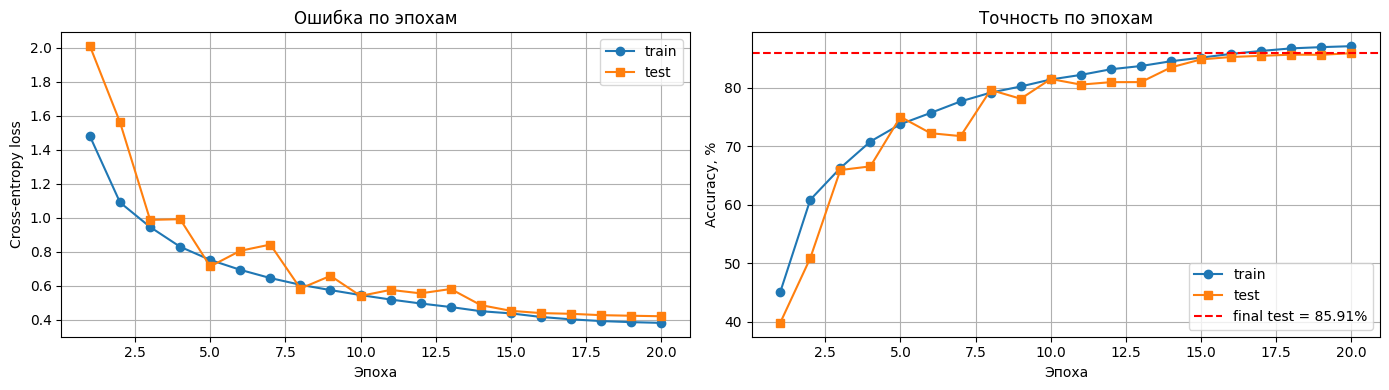

Суммарное время обучения: 2767.5 сек
Среднее время эпохи: 138.4 сек


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(history["epoch"], history["loss"], marker='o', label="train")
axes[0].plot(history["epoch"], history["test_loss"], marker='s', label="test")
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].set_title("Ошибка по эпохам")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history["epoch"], [a * 100 for a in history["train_acc"]], marker='o', label="train")
axes[1].plot(history["epoch"], [a * 100 for a in history["test_acc"]], marker='s', label="test")
axes[1].axhline(final_test_acc * 100, color='r', linestyle='--', label=f"final test = {final_test_acc*100:.2f}%")
axes[1].set_xlabel("Эпоха")
axes[1].set_ylabel("Accuracy, %")
axes[1].set_title("Точность по эпохам")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

print(f"Суммарное время обучения: {sum(history['time']):.1f} сек")
print(f"Среднее время эпохи: {np.mean(history['time']):.1f} сек")